# 05 · Primer clustering con K-Means (issue #14 · ML-02)

**Objetivo:** agrupar los 8.132 municipios en perfiles útiles para la ubicación industrial, usando las 4 variables acordadas con Elena (ver `docs/methodology/seleccion_variables_ml.md`).

**Variables:** población 2025, proporción de suelo industrial cartografiado, distancia a autovía y distancia a terminal ferroviaria de mercancías.

**Pasos:** huecos → log y recorte → escalado → PCA (≥ 85 % de varianza) → K-Means con K de 2 a 10 → elegir K → perfiles.

Este notebook va **separado** del de DBSCAN (`06`). El registro de experimentos en MLflow es el issue #15.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEMILLA = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'notebooks').is_dir())
DATA = ROOT / 'data/processed/sitewise_v03'
SALIDA = ROOT / 'data/processed/sitewise_ml'
assert (DATA / 'dataset_municipal.csv').exists(), 'Genera antes el dataset con los notebooks 01, 02 y 03'
pd.set_option('display.width', 200)
print('Datos en:', DATA.relative_to(ROOT))

Datos en: data\processed\sitewise_v03


## 1. Cargar las 4 variables

In [3]:
VARIABLES = [
    'poblacion_2025',
    'suelo_industrial_cartografiado_pct',
    'dist_recta_eje_autovia_km',
    'dist_recta_ttm_km',
]
ETIQUETAS = ['cod_ine', 'nombre', 'provincia', 'ccaa']

df = pd.read_csv(DATA / 'dataset_municipal.csv', dtype={'cod_ine': str}, usecols=ETIQUETAS + VARIABLES)
assert df['cod_ine'].is_unique and len(df) == 8132
X = df[VARIABLES].copy()

print('Municipios:', len(df))
print('Huecos por variable:')
print(X.isna().sum().to_string())

Municipios: 8132
Huecos por variable:
poblacion_2025                          0
suelo_industrial_cartografiado_pct      0
dist_recta_eje_autovia_km              56
dist_recta_ttm_km                     161


## 2. Huecos

In [4]:
# Las distancias sin dato (islas y 6 casos peninsulares) se rellenan con la distancia máxima observada.
# Este valor se usa SOLO para entrenar: la app mostrará siempre el dato observado y su estado.
sin_dato = X.isna()
X_ent = X.copy()
for c in ['dist_recta_eje_autovia_km', 'dist_recta_ttm_km']:
    X_ent[c] = X_ent[c].fillna(X_ent[c].max())

# El 0 de suelo industrial significa "sin polígonos en el catálogo", no "no hay suelo": no se toca.
print('Municipios con algún hueco rellenado:', int(sin_dato.any(axis=1).sum()))
print('Suelo industrial = 0:', f"{(X['suelo_industrial_cartografiado_pct'] == 0).mean():.1%}")

Municipios con algún hueco rellenado: 161
Suelo industrial = 0: 54.5%


## 3. Transformar: log y recorte

Población y distancias tienen muchos valores pequeños y unos pocos enormes. El logaritmo (`log(1 + x)`) acerca esos extremos, y el recorte a los percentiles 1-99 evita que unos pocos municipios (por ejemplo, las grandes ciudades) dominen la escala.

                                    antes  despues_log1p
poblacion_2025                      48.26           0.46
suelo_industrial_cartografiado_pct   7.89           2.87
dist_recta_eje_autovia_km            2.14          -0.27
dist_recta_ttm_km                    1.09          -0.77


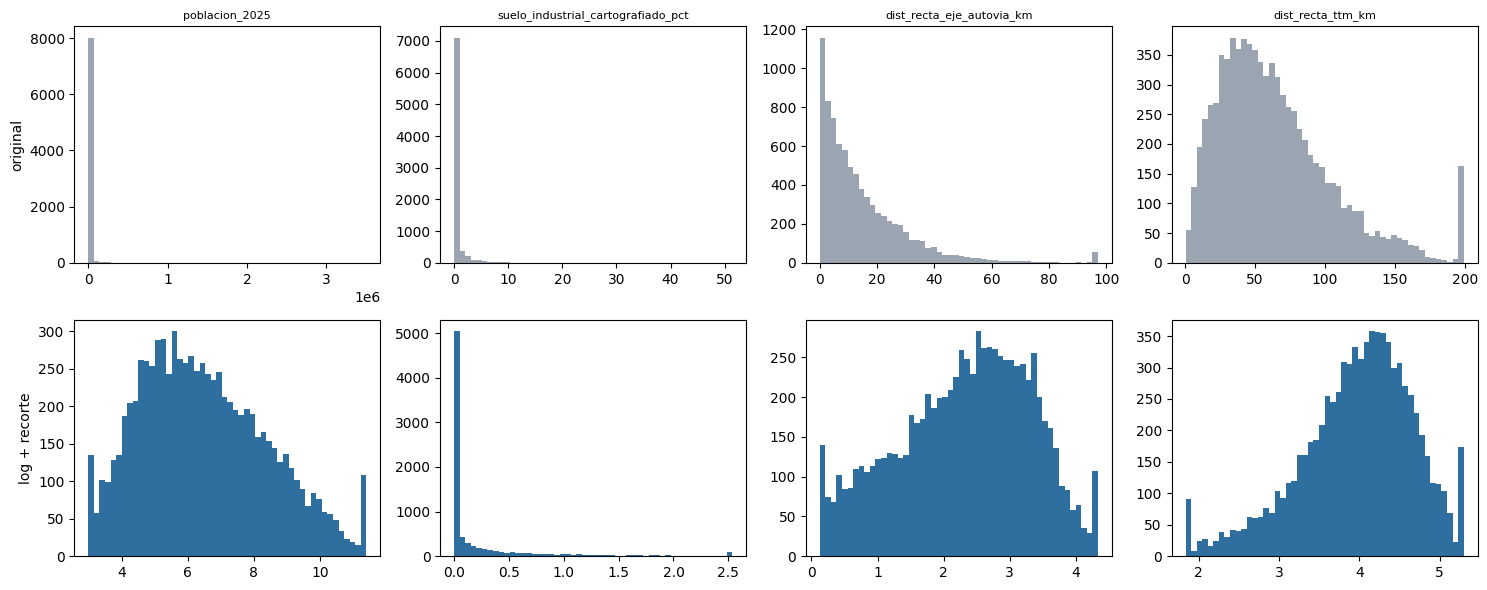

In [5]:
# Asimetría (skew) antes y después del log(1 + x). Un valor cercano a 0 es una distribución simétrica.
X_log = np.log1p(X_ent)
asimetria = pd.DataFrame({'antes': X_ent.skew(), 'despues_log1p': X_log.skew()}).round(2)
print(asimetria.to_string())

# Recorte a los percentiles 1-99 para que unos pocos municipios extremos no dominen la escala.
p1, p99 = X_log.quantile(0.01), X_log.quantile(0.99)
X_rec = X_log.clip(lower=p1, upper=p99, axis=1)

fig, ejes = plt.subplots(2, 4, figsize=(15, 6))
for j, c in enumerate(VARIABLES):
    ejes[0, j].hist(X_ent[c], bins=50, color='#9aa5b1'); ejes[0, j].set_title(c, fontsize=8)
    ejes[1, j].hist(X_rec[c], bins=50, color='#2f6f9f')
ejes[0, 0].set_ylabel('original'); ejes[1, 0].set_ylabel('log + recorte')
plt.tight_layout(); plt.show()

## 4. Escalar y reducir con PCA

`StandardScaler` deja cada variable con media 0 y desviación 1 para que ninguna pese más por su unidad. Después, PCA reduce a los componentes que explican al menos el 85 % de la varianza.

In [6]:
escalador = StandardScaler()
Z = pd.DataFrame(escalador.fit_transform(X_rec), columns=VARIABLES, index=df.index)
print('Media ~0 y desviación 1 tras escalar:')
print(Z.agg(['mean', 'std']).round(3).to_string())

# PCA: componentes necesarios para explicar al menos el 85 % de la varianza (requisito del enunciado).
pca = PCA(n_components=0.85, random_state=SEMILLA)
Zp = pca.fit_transform(Z)
print('Componentes:', pca.n_components_, '| varianza explicada:', pca.explained_variance_ratio_.round(3), '| acumulada:', pca.explained_variance_ratio_.sum().round(3))
print()
print('Peso de cada variable en cada componente:')
print(pd.DataFrame(pca.components_.T, index=VARIABLES, columns=[f'PC{i+1}' for i in range(pca.n_components_)]).round(2).to_string())

Media ~0 y desviación 1 tras escalar:
      poblacion_2025  suelo_industrial_cartografiado_pct  dist_recta_eje_autovia_km  dist_recta_ttm_km
mean            -0.0                                -0.0                        0.0                0.0
std              1.0                                 1.0                        1.0                1.0
Componentes: 3 | varianza explicada: [0.554 0.185 0.153] | acumulada: 0.892

Peso de cada variable en cada componente:
                                     PC1   PC2   PC3
poblacion_2025                      0.51  0.59  0.12
suelo_industrial_cartografiado_pct  0.54  0.35 -0.07
dist_recta_eje_autovia_km          -0.48  0.47  0.71
dist_recta_ttm_km                  -0.47  0.56 -0.69


## 5. K-Means con K de 2 a 10

Se prueba cada K y se miden cuatro cosas:
- **Inercia** (codo): cuánto se acercan los municipios a su centro. Siempre baja al subir K; se busca el punto donde deja de bajar mucho.
- **Silhouette** (más alto = mejor): lo separados que están los grupos.
- **Davies-Bouldin** (más bajo = mejor).
- **Calinski-Harabasz** (más alto = mejor).

      inercia  silhouette  davies_bouldin  calinski_harabasz  tam_grupo_menor_%
k                                                                              
2   17169.478       0.420           1.034           5604.785             24.988
3   13343.444       0.285           1.251           4770.920             14.879
4   11345.621       0.279           1.182           4217.309             13.724
5    9822.270       0.274           1.125           3968.190              7.083
6    8572.928       0.266           1.148           3873.623              5.878
7    7723.247       0.258           1.073           3731.710              5.275
8    7106.185       0.252           1.092           3576.699              4.956
9    6611.198       0.245           1.108           3439.511              4.808
10   6165.168       0.245           1.066           3343.403              3.505


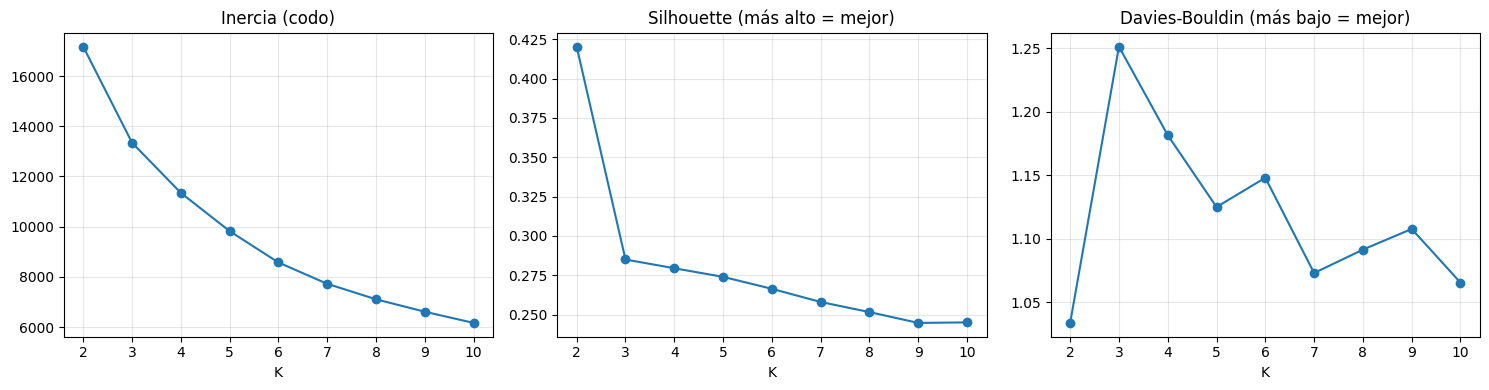

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Zp)
    filas.append({
        'k': k,
        'inercia': km.inertia_,
        'silhouette': silhouette_score(Zp, km.labels_),
        'davies_bouldin': davies_bouldin_score(Zp, km.labels_),
        'calinski_harabasz': calinski_harabasz_score(Zp, km.labels_),
        'tam_grupo_menor_%': np.bincount(km.labels_).min() / len(km.labels_) * 100,
    })
metricas = pd.DataFrame(filas).set_index('k')
print(metricas.round(3).to_string())

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
metricas['inercia'].plot(marker='o', ax=ejes[0], title='Inercia (codo)')
metricas['silhouette'].plot(marker='o', ax=ejes[1], title='Silhouette (más alto = mejor)')
metricas['davies_bouldin'].plot(marker='o', ax=ejes[2], title='Davies-Bouldin (más bajo = mejor)')
for e in ejes: e.set_xlabel('K'); e.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Elegir K

Lectura de la tabla anterior (ejecuta y comprueba que los números coinciden):

- **K = 2** tiene el mejor Silhouette, pero solo separa "municipios grandes" de "pequeños". Es correcto y poco útil para decidir ubicaciones.
- Del K = 3 en adelante el Silhouette baja a ~0,28 y se mantiene casi plano: **no hay grupos muy separados, sino un continuo** de municipios. Es normal con datos territoriales.
- El codo no es marcado. Se elige entonces por **utilidad e interpretabilidad**, mirando que los grupos tengan sentido y no sean minúsculos.

**Propuesta de trabajo: K = 5.** Los grupos se distinguen por tamaño, industria y conexión con autovía y ferrocarril, el menor tiene el 7 % de los municipios, y es estable con distintas semillas (ver abajo). K = 4 y K = 6 son alternativas razonables y se pueden probar cambiando `K_ELEGIDO`; es una decisión para revisar con Elena.

In [8]:
K_ELEGIDO = 5

km = KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=SEMILLA).fit(Zp)
df['grupo_bruto'] = km.labels_

# Etiquetas estables: se numeran de mayor a menor población mediana (1 = municipios más grandes),
# para que el número de grupo no dependa del azar de cada ejecución.
orden = df.groupby('grupo_bruto')['poblacion_2025'].median().sort_values(ascending=False).index
df['grupo'] = df['grupo_bruto'].map({g: i + 1 for i, g in enumerate(orden)})

# Estabilidad: ¿salen los mismos grupos con otras semillas? ARI = 1 significa idénticos.
from sklearn.metrics import adjusted_rand_score
otros = [KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=s).fit(Zp).labels_ for s in range(1, 6)]
ari = [adjusted_rand_score(km.labels_, o) for o in otros]
print('Estabilidad (ARI medio con 5 semillas):', round(float(np.mean(ari)), 3))

Estabilidad (ARI medio con 5 semillas): 0.988


## 7. Perfil de cada grupo

Mediana de cada variable **en unidades originales** (no escaladas), para poder leerlas.

In [9]:
def perfil(df, etiqueta):
    """Mediana de cada variable (en unidades originales), tamaño y % de municipios por grupo."""
    g = df.groupby(etiqueta)
    t = g[VARIABLES].median().round(2)
    t.insert(0, 'municipios', g.size())
    t.insert(1, '% del total', (g.size() / len(df) * 100).round(1))
    return t

tabla = perfil(df, 'grupo')
tabla

,municipios,% del total,poblacion_2025,suelo_industrial_cartografiado_pct,dist_recta_eje_autovia_km,dist_recta_ttm_km
grupo,,,,,,
1,576,7.1,13139.0,3.81,1.61,13.50
2,1091,13.4,5988.0,0.86,3.50,50.15
3,1707,21.0,800.0,0.00,9.31,27.46
4,3120,38.4,250.0,0.00,23.90,77.16
5,1638,20.1,193.5,0.00,4.67,68.53


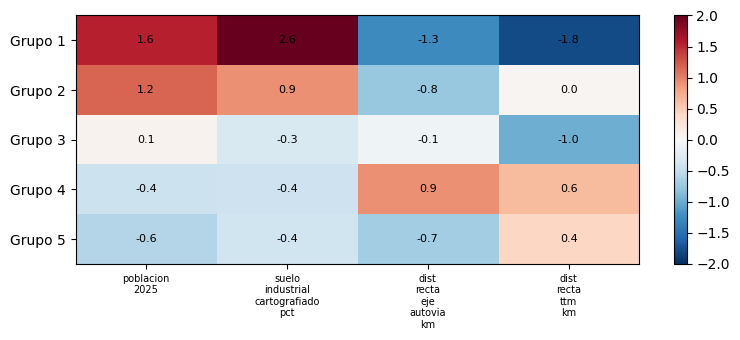

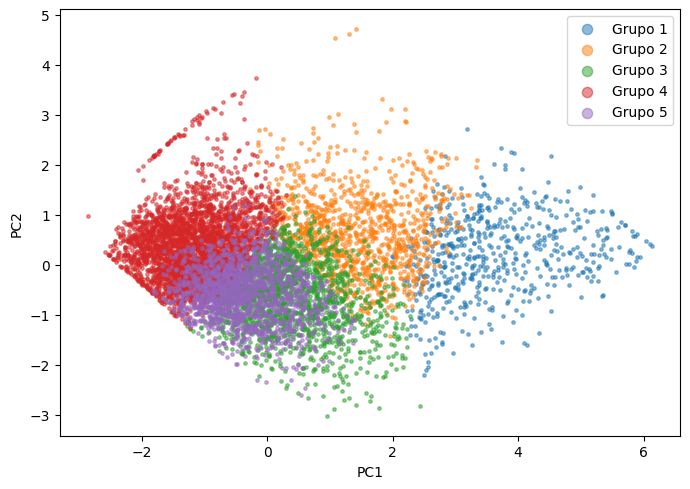

In [10]:
# Mapa de calor: cuánto se aleja cada grupo de la media (en desviaciones típicas; rojo = más alto, azul = más bajo).
medias_z = Z.assign(grupo=df['grupo']).groupby('grupo').mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
im = ax.imshow(medias_z.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(VARIABLES))); ax.set_xticklabels([v.replace('_', '\n') for v in VARIABLES], fontsize=7)
ax.set_yticks(range(len(medias_z))); ax.set_yticklabels([f'Grupo {g}' for g in medias_z.index])
for i in range(medias_z.shape[0]):
    for j in range(medias_z.shape[1]):
        ax.text(j, i, f'{medias_z.values[i, j]:.1f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

# Los grupos sobre los dos primeros componentes del PCA.
fig, ax = plt.subplots(figsize=(7, 5))
for g in sorted(df['grupo'].unique()):
    m = df['grupo'] == g
    ax.scatter(Zp[m, 0], Zp[m, 1], s=6, alpha=.5, label=f'Grupo {g}')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(markerscale=3); plt.tight_layout(); plt.show()

## 8. Lectura provisional de los grupos

Con K = 5 y los datos de esta ejecución, los grupos se leen así (a revisar con Elena; si cambias K o los datos, rehaz esta lectura con la tabla de arriba):

| Grupo | Lectura | Rasgos |
| --- | --- | --- |
| 1 | Polos grandes e industriales | Mayor población y proporción de suelo industrial; muy cerca de autovía y de terminal ferroviaria |
| 2 | Municipios grandes con algo de industria | Población alta, industria moderada, terminal ferroviaria más lejos (~50 km) |
| 3 | Pequeños y medianos bien conectados | Población de cientos, cerca de autovía y de terminal; sin suelo industrial cartografiado |
| 4 | Rurales aislados | Los más alejados de autovía y de ferrocarril |
| 5 | Rurales pequeños cerca de autovía | Autovía cerca, terminal ferroviaria lejos |

**Cautela:** más de la mitad de los municipios tiene `suelo_industrial = 0`, que significa "sin polígonos en el catálogo" y no "sin suelo". Por eso esta variable separa sobre todo a los grandes polos y no distingue bien entre los pequeños.

## 9. Comprobaciones

¿Los grupos reflejan perfiles reales o solo la geografía administrativa? Se mira cómo se reparten por comunidad autónoma y dónde caen los municipios con distancias rellenadas.

In [11]:
reparto = pd.crosstab(df['ccaa'], df['grupo'], normalize='index').mul(100).round(0).astype(int)
print('% de municipios de cada comunidad en cada grupo:')
print(reparto.to_string())

print()
print('Municipios con alguna distancia rellenada, por grupo:')
print(df.loc[sin_dato.any(axis=1), 'grupo'].value_counts().sort_index().to_string())

% de municipios de cada comunidad en cada grupo:
grupo                         1    2   3    4   5
ccaa                                             
Andalucía                     8   24  19   38  11
Aragón                        3    4  13   56  24
Asturias, Principado de      14   21  24   36   5
Balears, Illes                0   24   0   69   7
Canarias                      0   28   0   70   1
Cantabria                    21    7  59   10   4
Castilla y León               2    3  15   46  34
Castilla-La Mancha            2   12   9   60  18
Cataluña                     15   20  32   21  13
Ceuta                         0    0   0  100   0
Comunitat Valenciana         15   30  13   24  18
Extremadura                   1   11  14   56  18
Galicia                       8   24  42   19   7
Madrid, Comunidad de         26   17  30   11  16
Melilla                       0  100   0    0   0
Murcia, Región de            40   38  20    2   0
Navarra, Comunidad Foral de   9   13  60   12   7
P

## 10. Guardar el resultado

Se guarda en `data/processed/sitewise_ml/` (fuera de Git, como el resto de datos procesados).

In [12]:
SALIDA.mkdir(parents=True, exist_ok=True)
df[['cod_ine', 'grupo']].rename(columns={'grupo': 'grupo_kmeans'}).to_csv(SALIDA / 'clusters_kmeans_v01.csv', index=False)
tabla.to_csv(SALIDA / 'perfiles_kmeans_v01.csv')
print('Guardado en:', SALIDA.relative_to(ROOT))

Guardado en: data\processed\sitewise_ml


## Conclusiones y siguientes pasos

- Se usan 4 variables, con cobertura completa o casi completa; el empleo, el viento y el agua subterránea quedan para una segunda prueba.
- Los datos no forman grupos muy separados (Silhouette ~0,28 desde K = 3): son un continuo, y K = 5 es una elección razonada, no un óptimo estadístico.
- Pendiente: contrastar K y la lectura de los grupos con Elena, comparar con DBSCAN (`06`) y registrar los experimentos en MLflow (#15).